# Real Estate Investment Advisor: Exploratory Data Analysis

**Dataset:** `india_housing_prices.csv`, 250,000 property listings across 20 states and 42 cities.

This notebook covers:
1. Data understanding and cleaning checks
2. The 20 EDA questions from the brief (price & size, location, relationships, investment/amenities/ownership)
3. The investment-focused analyses from Approach Step 2
4. Statistical significance tests
5. Key insights and how they shaped the models

All analysis functions live in `src/eda.py`, so the same numbers feed the notebook, the report and the Streamlit
app. Charts are saved to `reports/figures/`. Run `python pipeline.py` first to create the cleaned dataset.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

import config
from src import eda
from src.cleaning import load_raw

pd.set_option("display.max_columns", 50, "display.width", 160)

def show(name):
    display(Image(filename=str(config.FIGURES_DIR / f"{name}.png")))

## 1. Data understanding

In [2]:
raw = load_raw()
print(raw.shape)
raw.head()

(250000, 23)


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


In [3]:
pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "unique": raw.nunique()})

,dtype,missing,unique
ID,int64,0,250000
State,str,0,20
City,str,0,42
Locality,str,0,500
Property_Type,str,0,3
BHK,int64,0,5
Size_in_SqFt,int64,0,4501
Price_in_Lakhs,float64,0,48700
Price_per_SqFt,float64,0,100
Year_Built,int64,0,34


In [4]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ID,250000.0,125000.50,72168.93,1.0,62500.75,125000.50,187500.25,250000.00
BHK,250000.0,3.00,1.42,1.0,2.00,3.00,4.00,5.00
Size_in_SqFt,250000.0,2749.81,1300.61,500.0,1623.00,2747.00,3874.00,5000.00
Price_in_Lakhs,250000.0,254.59,141.35,10.0,132.55,253.87,376.88,500.00
Price_per_SqFt,250000.0,0.13,0.13,0.0,0.05,0.09,0.16,0.99
Year_Built,250000.0,2006.52,9.81,1990.0,1998.00,2007.00,2015.00,2023.00
Floor_No,250000.0,14.97,8.95,0.0,7.00,15.00,23.00,30.00
Total_Floors,250000.0,15.50,8.67,1.0,8.00,15.00,23.00,30.00
Age_of_Property,250000.0,18.48,9.81,2.0,10.00,18.00,27.00,35.00
Nearby_Schools,250000.0,5.50,2.88,1.0,3.00,5.00,8.00,10.00


**Observations**
- 250,000 rows × 23 columns. **No missing values** and **no duplicate rows** (also none when ignoring `ID`).
- Every numeric column is spread evenly between its minimum and maximum (e.g. price 10–500 lakhs, size 500–5,000 sq ft),
  and every category has almost exactly equal counts. That is the signature of **synthetic, uniformly generated data**.
- `Price_per_SqFt` is stored **in lakhs** and rounded to 2 decimals (median 0.09 = about ₹9,000/sq ft).
- `Age_of_Property` = 2025 − `Year_Built` in every row.

In [5]:
print("Floor_No > Total_Floors:", (raw["Floor_No"] > raw["Total_Floors"]).sum(), "rows")
print("Cities per locality (mean):", raw.groupby("Locality")["City"].nunique().mean())
print("States per city (max):", raw.groupby("City")["State"].nunique().max())

Floor_No > Total_Floors: 116304 rows
Cities per locality (mean): 41.998
States per city (max): 1


Two data-quality problems:
- **46.5% of rows have the floor number above the building's total floors**, which is impossible. The values look
  swapped at entry, so cleaning swaps them back instead of dropping half the dataset.
- **`Locality` is not a real location**: each of its 500 values appears in all 42 cities. It is kept for display but
  excluded from the models. `State` is redundant because each city belongs to exactly one state.

In [6]:
report = json.loads(config.CLEANING_REPORT_PATH.read_text())
{k: report[k] for k in ["raw_shape", "missing_before", "duplicates_removed", "floor_above_total_floors",
                        "age_mismatches", "outliers_iqr", "clean_shape", "engineered_shape", "good_investment_rate_pct"]}

{'raw_shape': [250000, 23],
 'missing_before': {},
 'duplicates_removed': {'exact': 0, 'same_listing_different_id': 0},
 'floor_above_total_floors': {'rows': 116304, 'pct': 46.52, 'action': 'swap'},
 'age_mismatches': 0,
 'outliers_iqr': {'Price_in_Lakhs': {'lower_fence': -233.94,
   'upper_fence': 743.38,
   'outliers': 0},
  'Size_in_SqFt': {'lower_fence': -1753.5,
   'upper_fence': 7250.5,
   'outliers': 0},
  'Price_per_SqFt': {'lower_fence': -11973.99,
   'upper_fence': 32764.22,
   'outliers': 19723}},
 'clean_shape': [250000, 24],
 'engineered_shape': [250000, 47],
 'good_investment_rate_pct': 27.06}

In [7]:
df = eda.load()
print(df.shape)
df[["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt", "PPSF_vs_City_Median", "Infrastructure_Score",
    "Amenity_Count", "Amenity_Density_Score", "City_Tier", "Annual_Growth_Rate", "Future_Price_5Y", "Good_Investment"]].describe().T.round(2)

(250000, 47)


,count,mean,std,min,25%,50%,75%,max
Price_in_Lakhs,250000.0,254.59,141.35,10.00,132.55,253.87,376.88,500.00
Size_in_SqFt,250000.0,2749.81,1300.61,500.00,1623.00,2747.00,3874.00,5000.00
Price_per_SqFt,250000.0,13058.28,13071.85,202.25,4802.84,9244.75,15987.39,99182.00
PPSF_vs_City_Median,250000.0,1.41,1.41,0.02,0.52,1.00,1.73,10.89
Infrastructure_Score,250000.0,53.35,19.21,6.67,40.00,53.33,66.67,100.00
Amenity_Count,250000.0,3.00,1.41,1.00,2.00,3.00,4.00,5.00
Amenity_Density_Score,250000.0,1.54,1.44,0.20,0.64,1.09,1.85,10.00
City_Tier,250000.0,1.80,0.40,1.00,2.00,2.00,2.00,2.00
Annual_Growth_Rate,250000.0,8.14,1.36,2.02,7.19,8.14,9.09,14.07
Future_Price_5Y,250000.0,377.08,211.17,12.74,195.85,374.52,555.83,891.58


**Cleaning and feature engineering summary** (`src/cleaning.py`, `src/features.py`, `src/targets.py`)
- Text trimmed, category labels made readable (`Under_Construction` → `Under Construction`), amenity lists normalised.
- Numeric columns type-checked; median/mode imputation in place (nothing needed imputing).
- `Price_per_SqFt` recomputed exactly, **in rupees**.
- New features: `Log_Price`, `PPSF_vs_City_Median`, `City_Tier`, `Floor_Ratio`, `Transport_Score`, `Furnished_Level`,
  binary flags, five `Has_<amenity>` columns, `Amenity_Count`, `Amenity_Density_Score` (amenities per 1,000 sq ft)
  and `Infrastructure_Score` (0–100 from schools, hospitals and transport).
- Targets: `Annual_Growth_Rate` → `Future_Price_5Y = Price × (1 + r)^5`, and `Good_Investment`
  (growth ≥ 8% **and** price per sq ft ≤ city median). The rules are documented in `config.py` and the README.

## 2. EDA questions
### 2.1 Price & size analysis (Q1–Q5)

### Q1. What is the distribution of property prices?

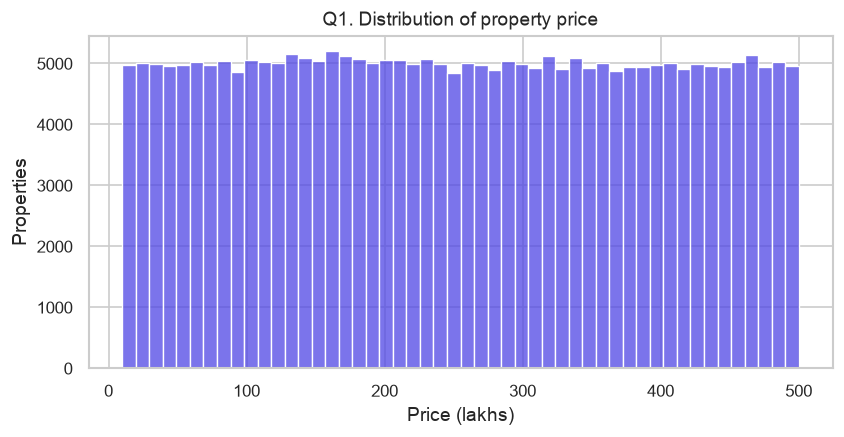

In [8]:
t, _ = eda.q01_price_distribution(df); t
show('q01_price_distribution')

**Answer.** Prices are spread **evenly from ₹10 L to ₹500 L** (mean ≈ median ≈ ₹254.6 L, skew ≈ 0). There is no long right tail like a real market would show: the distribution is uniform.

### Q2. What is the distribution of property sizes?

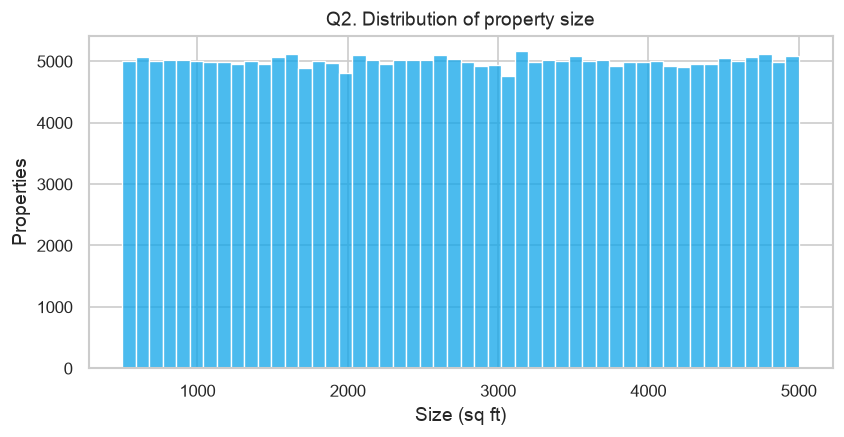

In [9]:
t, _ = eda.q02_size_distribution(df); t
show('q02_size_distribution')

**Answer.** Sizes are also **uniform between 500 and 5,000 sq ft** (mean ≈ median ≈ 2,750 sq ft, skew 0).

### Q3. How does the price per sq ft vary by property type?

,count,mean,median
Property_Type,,,
Apartment,82956,13047.0,9245.0
Independent House,83300,13102.0,9305.0
Villa,83744,13026.0,9190.0


Kruskal-Wallis p = 0.0186


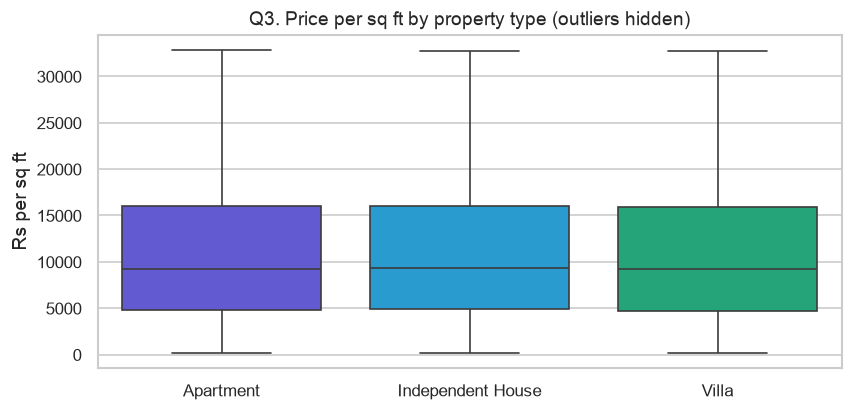

In [10]:
t, _ = eda.q03_ppsf_by_property_type(df); display(t); print('Kruskal-Wallis p =', round(t.attrs['kruskal_p'], 4))
show('q03_ppsf_by_property_type')

**Answer.** Medians are within about 1% of each other (~₹9,200–9,300/sq ft) for apartments, independent houses and villas. The Kruskal-Wallis p-value is small only because n = 250,000: the difference is **statistically detectable but practically meaningless**. Property type does not set price per sq ft in this data.

### Q4. Is there a relationship between property size and price?

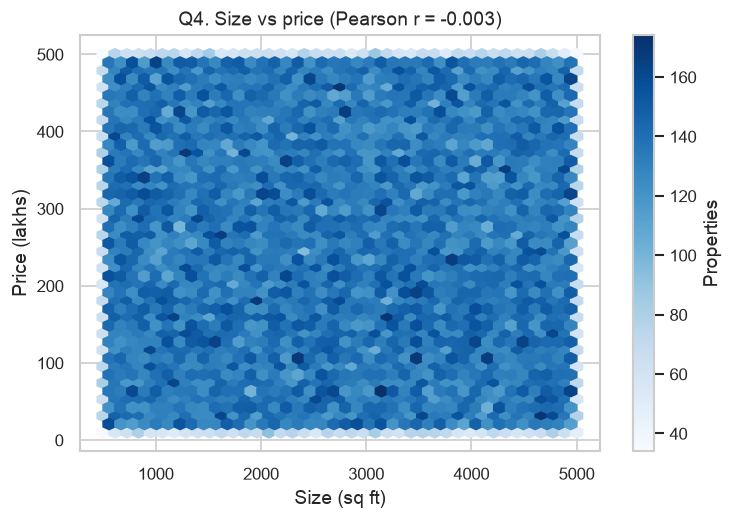

In [11]:
t, _ = eda.q04_size_vs_price(df); t
show('q04_size_vs_price')

**Answer.** **No.** Pearson r ≈ 0.00 (p ≈ 0.2) and Spearman ρ ≈ 0: a 5,000 sq ft home is no more expensive on average than a 500 sq ft one. Because price and size are independent, **price per sq ft varies mostly with size**: big homes are much cheaper per sq ft.

### Q5. Are there any outliers in price per sq ft or property size?

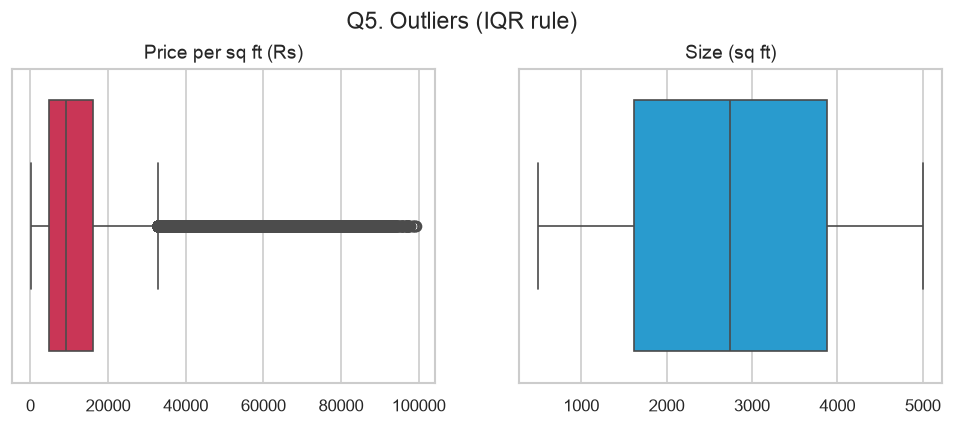

In [12]:
t, _ = eda.q05_outliers(df); t
show('q05_outliers')

**Answer.** Size and price have **no outliers** (both bounded and uniform). Price per sq ft has **19,723 IQR outliers (7.9%)** above ₹32,764/sq ft, up to ₹99,182. They are genuine combinations (a small home at a high price), so they were **flagged (`Is_PPSF_Outlier`) but kept**; tree models are robust to them and linear models use `Log_Price`.

### 2.2 Location-based analysis (Q6–Q10)

### Q6. What is the average price per sq ft by state?

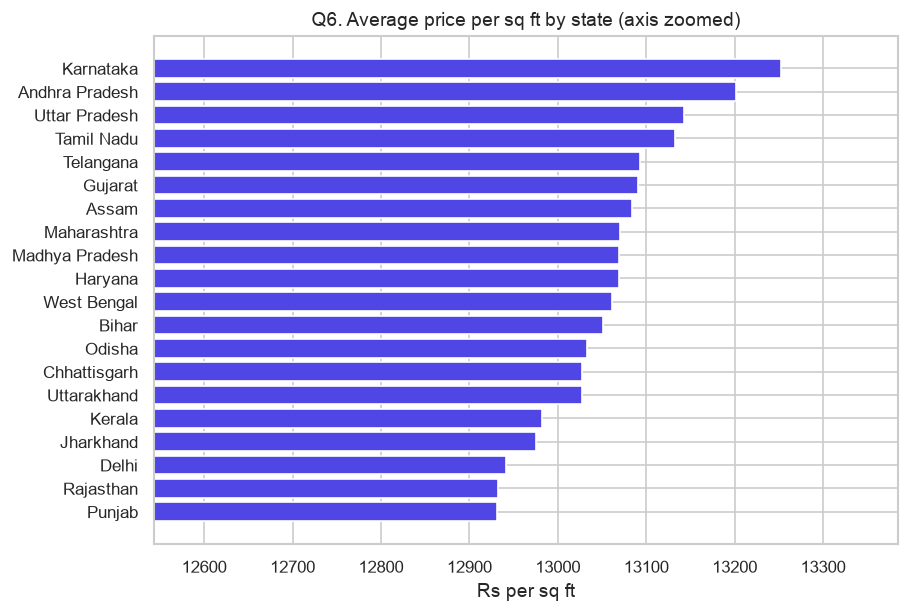

In [13]:
t, _ = eda.q06_ppsf_by_state(df); t.T
show('q06_ppsf_by_state')

**Answer.** All 20 states fall in a narrow band, about **₹12,930–13,250/sq ft (±1.2%)**. Karnataka and Andhra Pradesh are highest, Punjab and Rajasthan lowest, but the gap is tiny.

### Q7. What is the average property price by city?

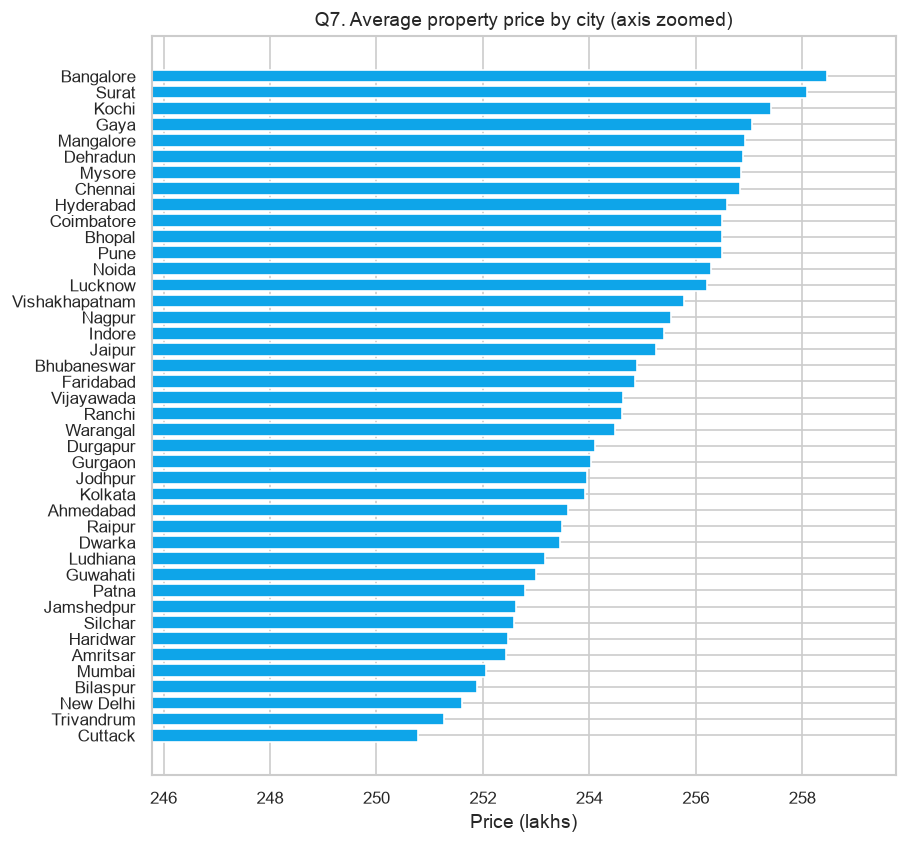

In [14]:
t, _ = eda.q07_price_by_city(df); pd.concat([t.head(5), t.tail(5)])
show('q07_price_by_city')

**Answer.** City averages range only from about **₹250.8 L to ₹258.5 L (3%)**. Mumbai is no pricier than Silchar: the raw data carries **no real location premium**. That is why location enters the targets through a documented city-tier rule rather than being learned from prices.

### Q8. What is the median age of properties by locality?

,localities,cities_per_locality_avg,median_age_min,median_age_max,overall_median_age
0,500,42.0,16.0,21.0,18.0


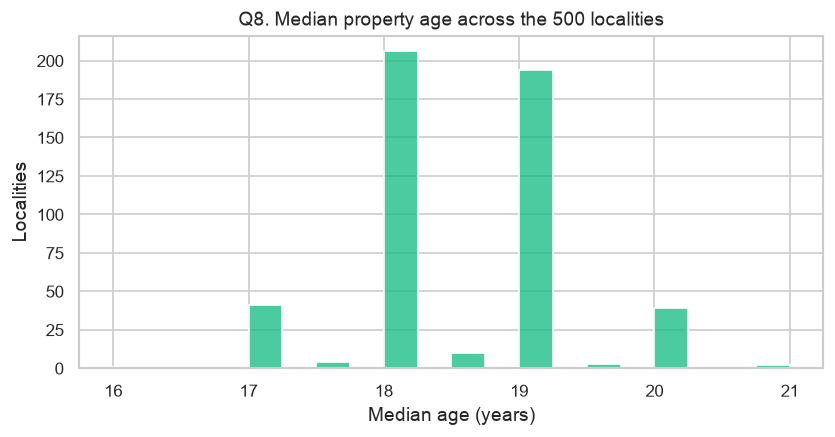

In [15]:
s, t, _ = eda.q08_median_age_by_locality(df); display(s); pd.concat([t.head(3), t.tail(3)]).to_frame('median_age')
show('q08_median_age_by_locality')

**Answer.** Median age by locality ranges from **16 to 21 years** around an overall median of 18. Each locality name appears in all 42 cities, so locality is a label, not a neighbourhood.

### Q9. How is BHK distributed across cities?

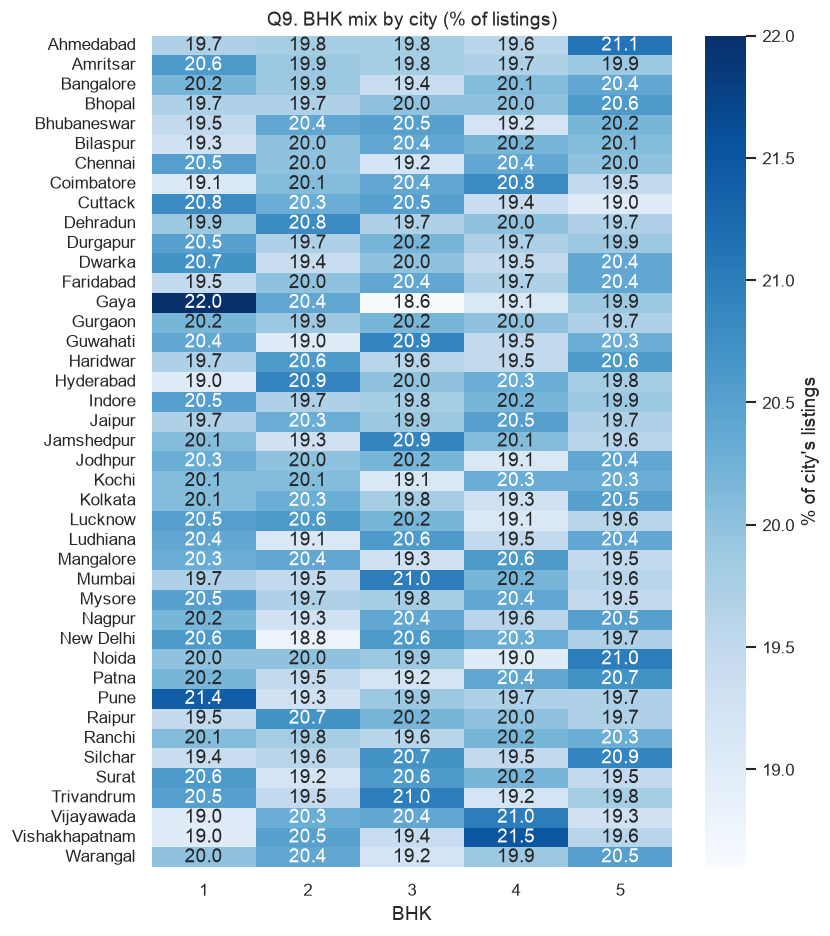

In [16]:
t, _ = eda.q09_bhk_by_city(df); t.describe().round(1)
show('q09_bhk_by_city')

**Answer.** Every city has roughly **20% of each BHK (1–5)**, between 18.6% and 22.0% in every cell. There is no city skewed towards small or large homes.

### Q10. What are the price trends for the top 5 most expensive localities?

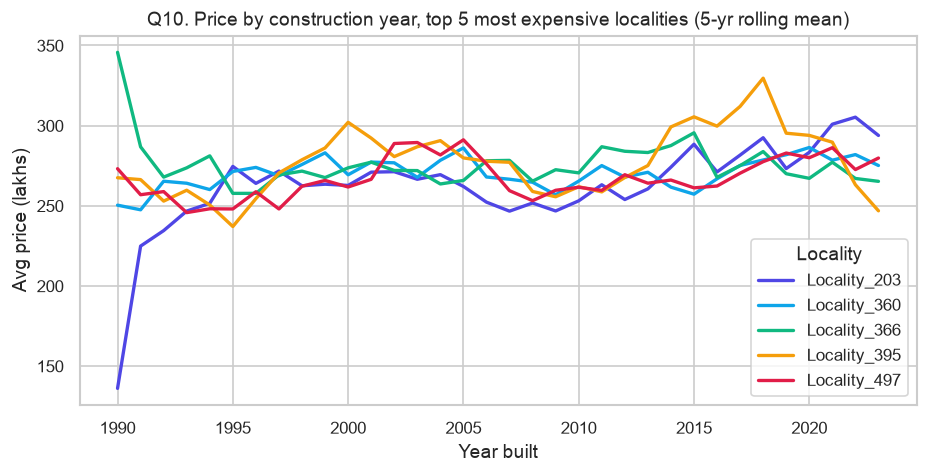

In [17]:
t, _ = eda.q10_top_locality_trends(df); t
show('q10_top_locality_trends')

**Answer.** The top 5 localities average ₹268–275 L. There are no sale dates, so construction year is the only time axis. Their prices by year built go up and down with no consistent trend: the differences are sampling noise, not a market trend.

### 2.3 Feature relationships & correlation (Q11–Q15)

### Q11. How are numeric features correlated with each other?

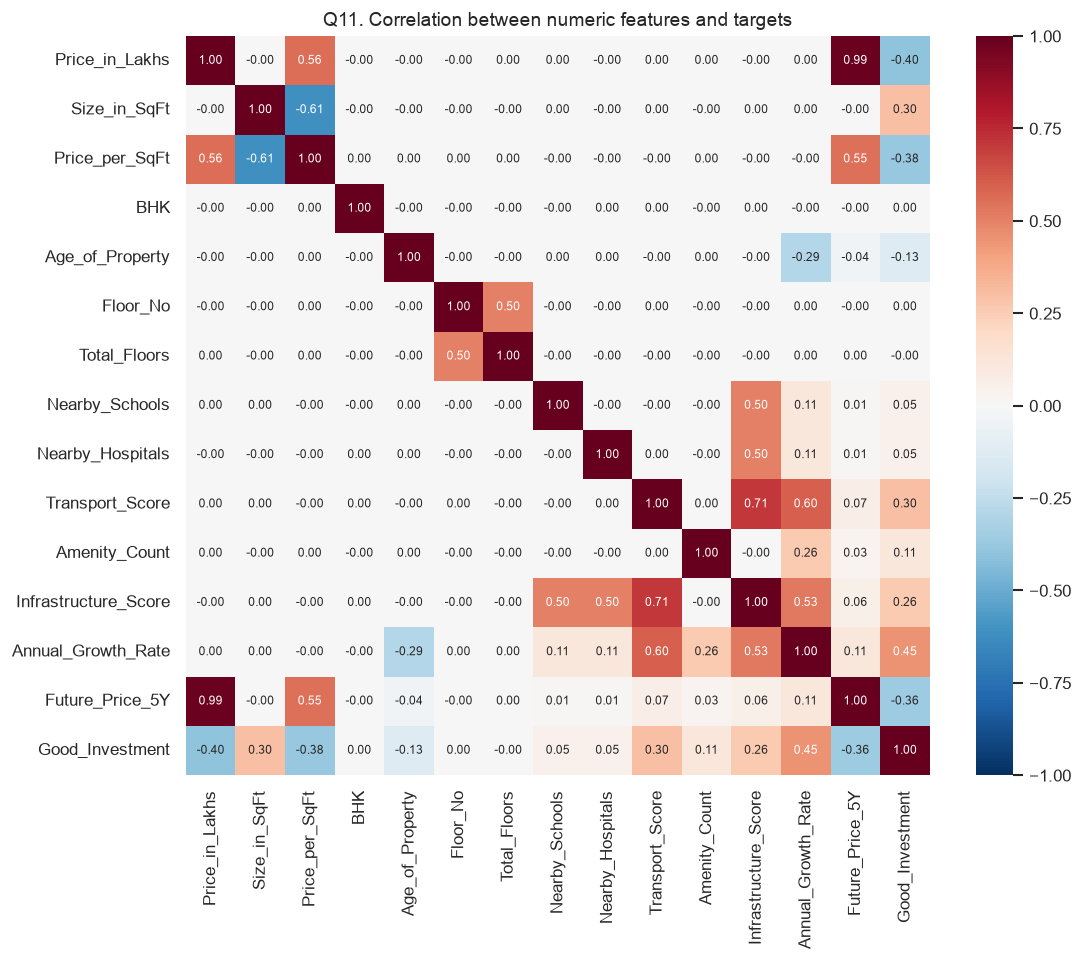

In [18]:
t, _ = eda.q11_correlation(df); t.loc[['Annual_Growth_Rate', 'Good_Investment']].T
show('q11_correlation')

**Answer.** **The raw features are uncorrelated with each other** (|r| < 0.01 everywhere). The structure is in the engineered features and targets: growth rises with transport (r ≈ 0.60) and infrastructure (≈ 0.53) and falls with age (≈ −0.29). `Good_Investment` is negatively related to price (≈ −0.40) and price per sq ft (≈ −0.38), and positively to size (≈ +0.30) and transport (≈ +0.30). Future price is almost entirely today's price (r ≈ 0.99).

### Q12. How do nearby schools relate to price per sq ft?

r = -0.0001 p = 0.977


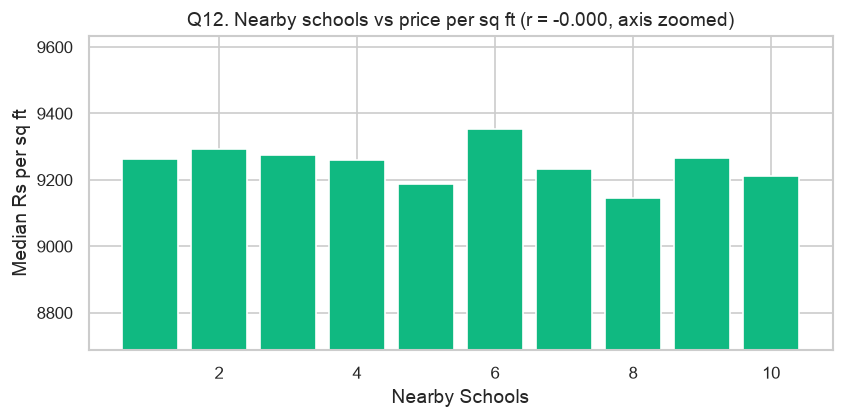

In [19]:
t, _ = eda.q12_schools_vs_ppsf(df); print('r =', round(t.attrs['pearson_r'], 4), 'p =', round(t.attrs['p_value'], 3)); t.T
show('q12_schools_vs_ppsf')

**Answer.** **No relationship** (r ≈ 0.00, p ≈ 0.98). Median price per sq ft is ≈ ₹9,150–9,350 whether there is 1 school or 10.

### Q13. How do nearby hospitals relate to price per sq ft?

r = -0.0001 p = 0.951


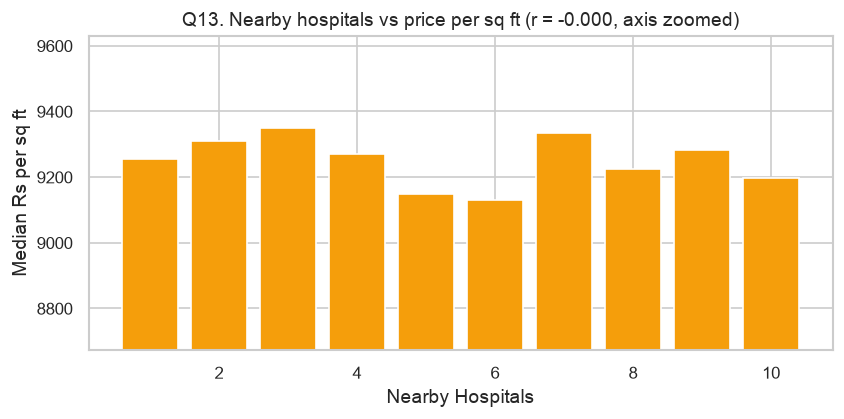

In [20]:
t, _ = eda.q13_hospitals_vs_ppsf(df); print('r =', round(t.attrs['pearson_r'], 4), 'p =', round(t.attrs['p_value'], 3)); t.T
show('q13_hospitals_vs_ppsf')

**Answer.** **No relationship** either (r ≈ 0.00, p ≈ 0.95). Schools and hospitals matter in this project through *appreciation* (Infrastructure Score), not today's price.

### Q14. How does price vary by furnished status?

ANOVA p = 0.609


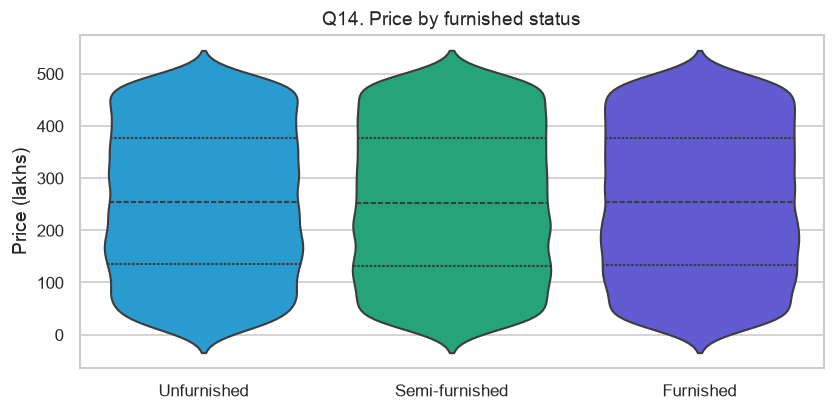

In [21]:
t, _ = eda.q14_price_by_furnished(df); print('ANOVA p =', round(t.attrs['anova_p'], 3)); t
show('q14_price_by_furnished')

**Answer.** Average prices are ₹253.8–254.5 L for all three levels (ANOVA p ≈ 0.6). **Furnishing does not change price.**

### Q15. How does price per sq ft vary by property facing direction?

Kruskal-Wallis p = 0.346


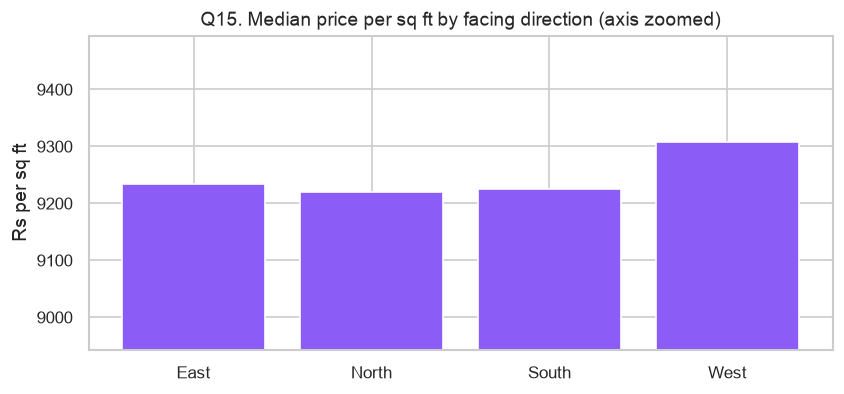

In [22]:
t, _ = eda.q15_ppsf_by_facing(df); print('Kruskal-Wallis p =', round(t.attrs['kruskal_p'], 3)); t
show('q15_ppsf_by_facing')

**Answer.** No meaningful difference (medians ≈ ₹9,220–9,310, p ≈ 0.35). Facing (Vastu) carries no price premium here.

### 2.4 Investment, amenities & ownership (Q16–Q20)

### Q16. How many properties belong to each owner type?

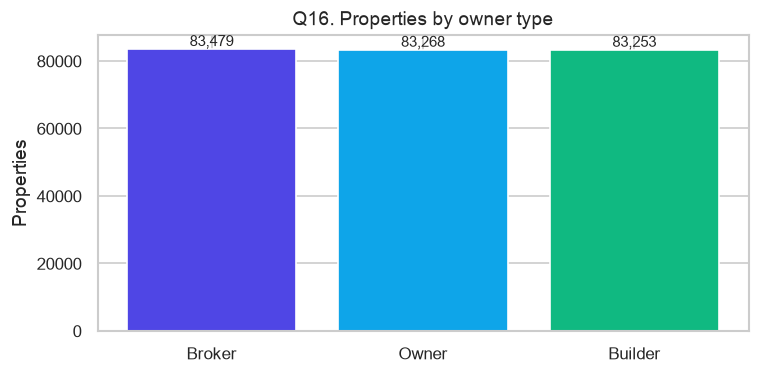

In [23]:
t, _ = eda.q16_owner_type(df); t
show('q16_owner_type')

**Answer.** An almost exact three-way split: **Broker 83,479, Owner 83,268, Builder 83,253** (≈ 33.3% each).

### Q17. How many properties are available under each availability status?

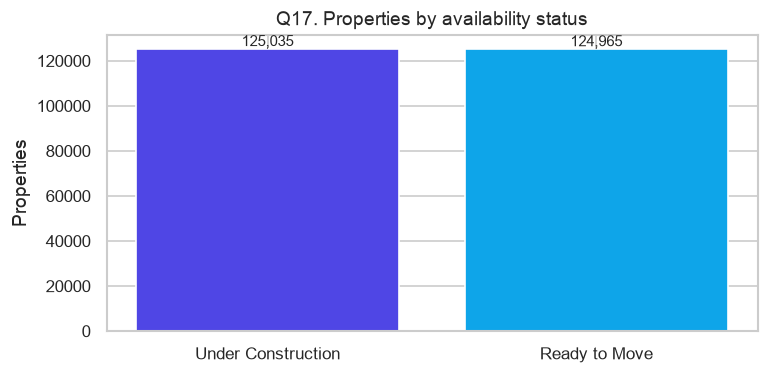

In [24]:
t, _ = eda.q17_availability(df); t
show('q17_availability')

**Answer.** **125,035 under construction and 124,965 ready to move** (50/50). The raw file has no 'Sold' status.

### Q18. Does parking space affect property price?

Welch t-test p = 0.576


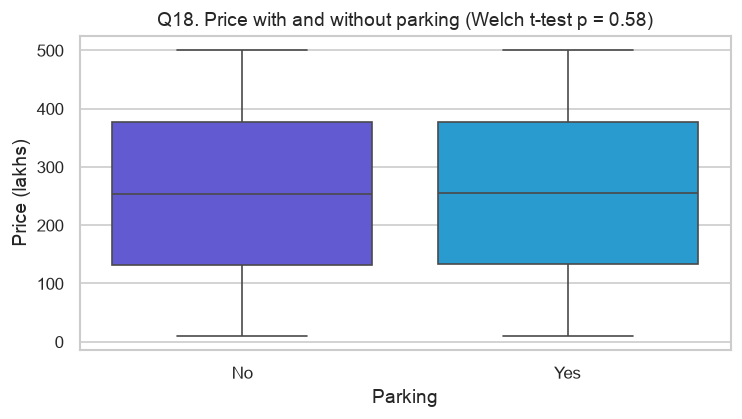

In [25]:
t, _ = eda.q18_parking_vs_price(df); print('Welch t-test p =', round(t.attrs['p_value'], 3)); t
show('q18_parking_vs_price')

**Answer.** **No.** Average price is ₹253.9 L without parking and ₹254.3 L with it (Welch t-test p ≈ 0.58).

### Q19. How do amenities affect price per sq ft?

Amenity_Count,1,2,3,4,5
median_ppsf_by_count,9240.0,9242.0,9207.0,9250.0,9294.0


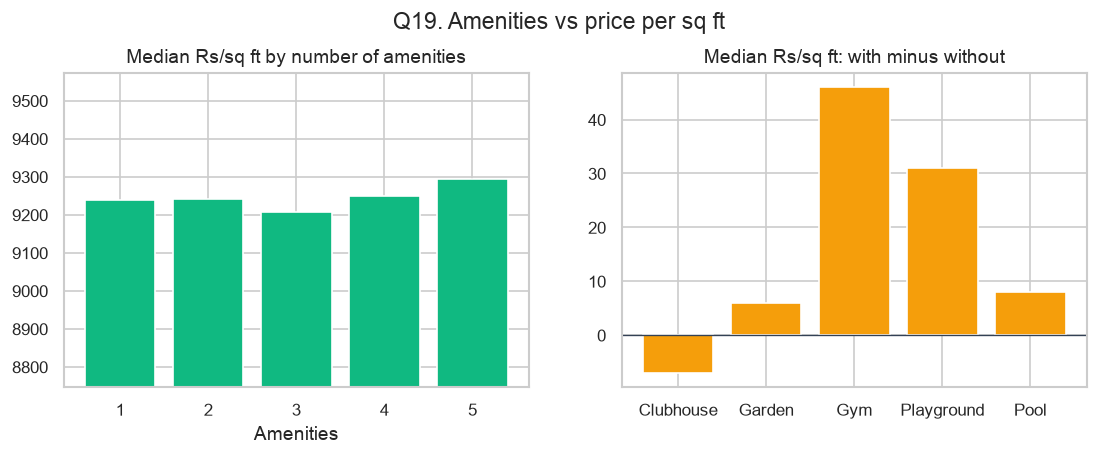

In [26]:
a, b, _ = eda.q19_amenities_vs_ppsf(df); display(a.T); b.T
show('q19_amenities_vs_ppsf')

**Answer.** Barely at all. Median price per sq ft is ≈ ₹9,200–9,300 for 1 to 5 amenities, and having any one amenity moves the median by less than ₹50 (< 0.5%). Like schools and hospitals, amenities matter for **appreciation**, not today's price.

### Q20. How does public transport accessibility relate to price per sq ft or investment potential?

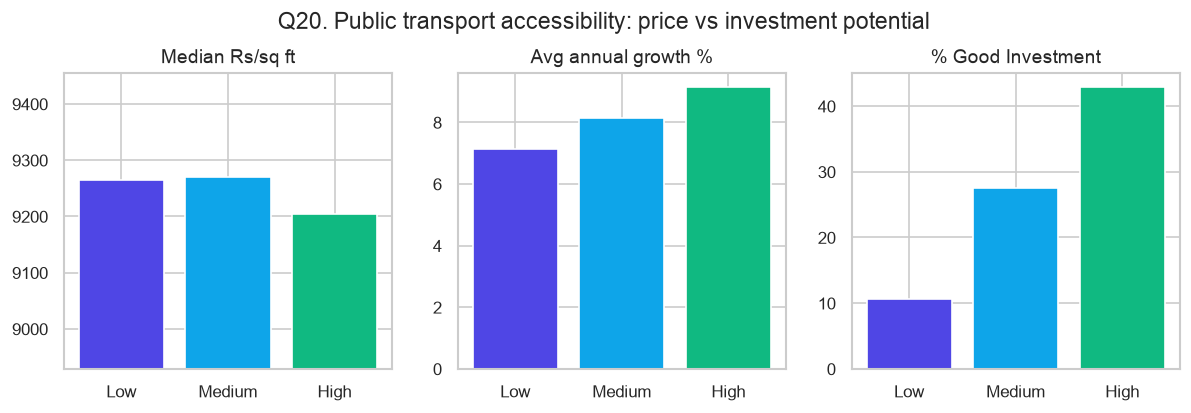

In [27]:
t, _ = eda.q20_transport(df); t
show('q20_transport')

**Answer.** Price per sq ft is the same at every level (≈ ₹9,200–9,270), but **investment potential is very different**: average growth climbs from 7.1% (low) to 8.1% (medium) to 9.1% (high), and the share of Good Investments from **10.7% to 27.5% to 42.9%**. Transport is the strongest single driver of the classification.

## 3. Investment-focused analyses (Approach Step 2)

### Price and investment trends by city

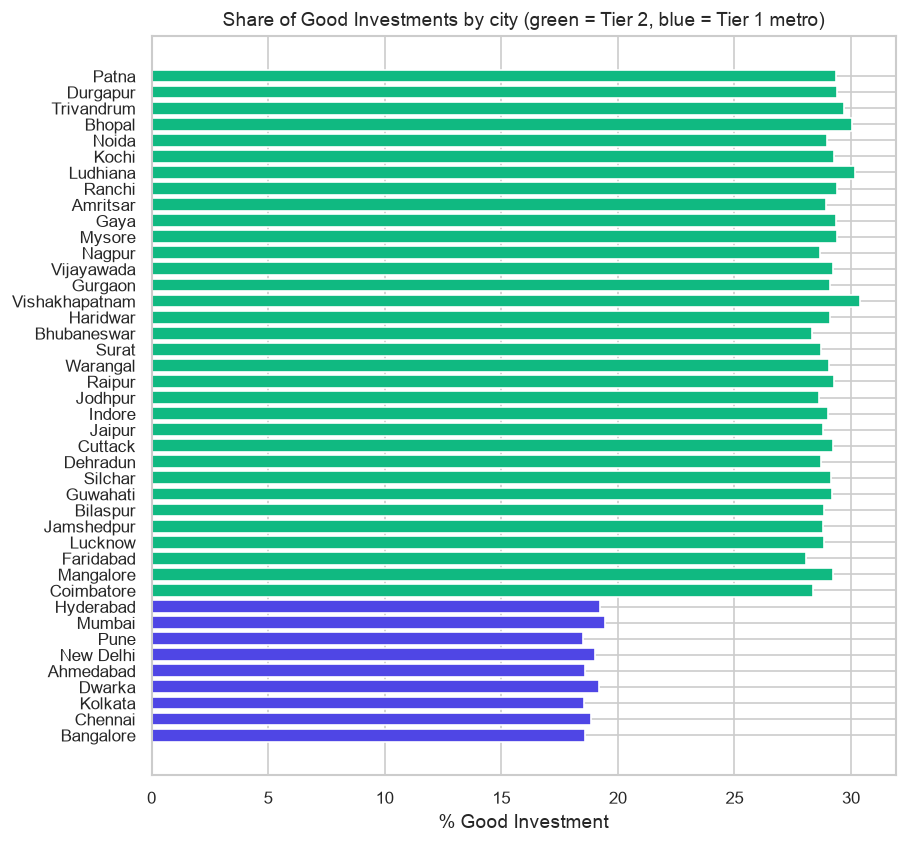

In [28]:
t, _ = eda.investment_by_city(df); pd.concat([t.head(5), t.tail(5)])
show('s1_investment_by_city')

**Answer.** Tier 2 (developing) cities average **8.3% growth and 29.1% Good Investments**; the eight Tier 1 metros average **7.5% and 18.9%**. Raw prices are the same everywhere, so the gap comes from the growth premium of developing markets plus the price-vs-city-median test.

### Correlation between area and investment return

,avg_growth_pct,median_ppsf,good_investment_pct
Size_in_SqFt,,,
<=1k,8.14,34141.92,6.53
1-2k,8.13,16900.64,14.27
2-3k,8.14,10112.40,24.85
3-4k,8.14,7231.89,34.69
4-5k,8.14,5620.59,44.76


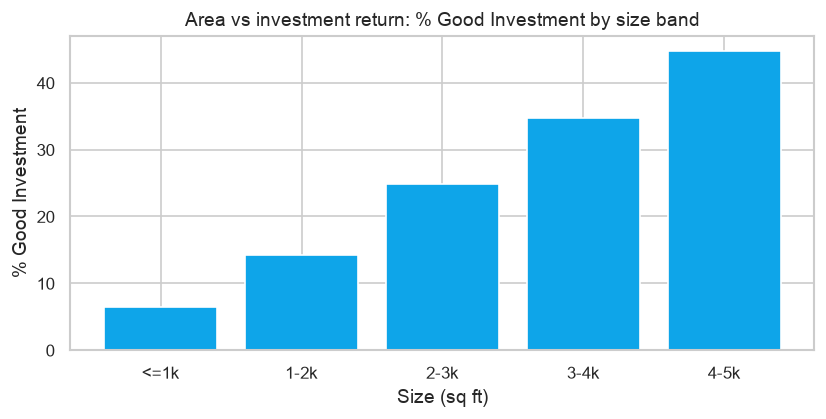

In [29]:
t, corr, _ = eda.area_vs_return(df); display(t); corr
show('s2_area_vs_return')

**Answer.** Area has **no effect on the growth rate** (r ≈ 0.00) but a strong effect on being a Good Investment (r ≈ +0.30): the share rises from 6.5% for homes under 1,000 sq ft to 44.8% for 4,000–5,000 sq ft, because larger homes cost far less per sq ft and so pass the 'not overpriced' test.

### Impact of crime rate on good investment classification
The dataset has **no crime-rate column**, so this cannot be measured directly. The closest proxy is `Security`
(gated / CCTV / guard):

In [30]:
eda.security_vs_investment(df)

,avg_growth_pct,good_investment_pct
Security,,
No,8.01,25.29
Yes,8.26,28.82


**Answer.** Secured properties show slightly higher growth (8.26% vs 8.01%) and Good Investment share (28.8% vs 25.3%). With real data, a locality-level crime index would be a valuable added feature.

### Relationship between infrastructure score and resale value

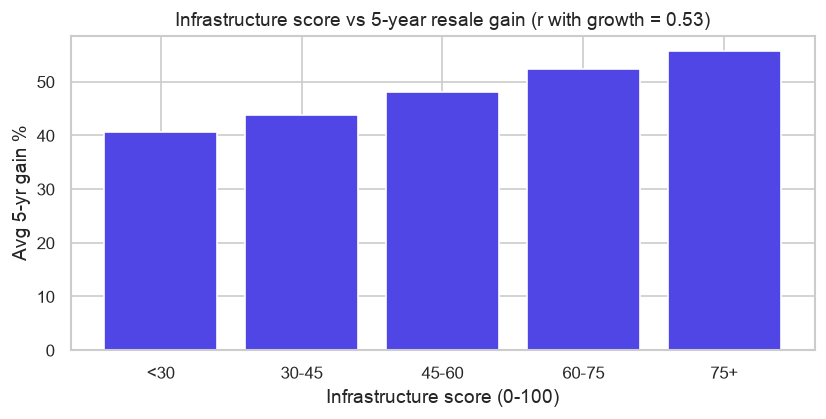

In [31]:
t, _ = eda.infrastructure_vs_resale(df); t
show('s3_infrastructure_vs_resale')

**Answer.** A clear, steady relationship: the expected 5-year gain rises from **≈41% (score < 30) to ≈56% (score 75+)**, and the Good Investment share from 9.7% to 43.9%. Better schools, hospitals and transport mean higher resale value.

## 4. Statistical significance
With 250,000 rows almost any difference gets a tiny p-value, so effect sizes (Cramér's V, correlation) are reported
alongside p-values.

**Chi-square test of independence**: is each categorical feature related to `Good_Investment`?

In [32]:
eda.chi_square_tests(df)

,chi2,dof,p_value,cramers_v,significant_at_5pct
feature,,,,,
Public_Transport_Accessibility,21918.5,2,0.000000e+00,0.2961,True
Availability_Status,3672.5,1,0.000000e+00,0.1212,True
City_Tier,2123.0,1,0.000000e+00,0.0922,True
Property_Type,1105.5,2,8.943333e-241,0.0665,True
Security,394.3,1,9.724187e-88,0.0397,True
Parking_Space,357.1,1,1.203453e-79,0.0378,True
Owner_Type,0.6,2,7.385452e-01,0.0016,False
Furnished_Status,0.3,2,8.506203e-01,0.0011,False
Facing,0.1,3,9.859674e-01,0.0008,False


- **Significant, with a real effect:** transport (V ≈ 0.30), availability (≈ 0.12), city tier (≈ 0.09), property type
  (≈ 0.07), security and parking (≈ 0.04).
- **Not significant:** owner type, furnishing and facing (p > 0.7). They are independent of the target, and the
  models' feature importance agrees.

In [33]:
eda.group_difference_tests(df)

,question,statistic,p_value
test,,,
Welch t-test,Growth: under construction vs ready to move,143.1507,0.000000
One-way ANOVA,Growth across transport levels,70905.7182,0.000000
Kruskal-Wallis,Price per sq ft across the 42 cities,36.6734,0.663250
Pearson correlation,Size vs price,-0.0025,0.206133


- **Welch t-test:** under-construction properties grow significantly faster than ready-to-move ones (p ≈ 0). Welch's
  version is used because it does not assume equal variances.
- **One-way ANOVA:** growth differs significantly across the three transport levels.
- **Kruskal-Wallis** (non-parametric, since price per sq ft is heavily skewed): **no** significant difference in price
  per sq ft across the 42 cities (p ≈ 0.66), confirming there is no location premium in raw prices.
- **Pearson:** size and price are uncorrelated (p ≈ 0.2).

## 5. Key insights
1. **The raw data is synthetic and independent.** Price, size, location, amenities and every other column are
   uniformly distributed and uncorrelated. No raw column on its own explains today's price.
2. **Locality is meaningless** (each value appears in all 42 cities) and was excluded from the models; **floor
   numbers were corrupted** in 46.5% of rows and repaired.
3. **Price per sq ft is driven by size**, because price and size are independent. Larger homes are therefore far more
   likely to be priced below their city's median.
4. **Investment potential comes from connectivity and infrastructure.** Transport, schools, hospitals, amenities,
   availability and city tier drive the growth rate, and therefore both targets.
5. **Tier 2 (developing) cities** offer more Good Investments (29%) than the metros (19%).
6. **Facing, owner type and furnishing** have no relationship with price or with the target.

**Impact on modelling**
- Drop `Locality`, `State` and `Year_Built` (redundant or meaningless); keep the engineered features.
- The classes are **73:27**, so use a stratified split, class weights, and compare models on **ROC AUC / F1**, not
  accuracy.
- Future price is multiplicative (price × growth), so **model it in log space**.
- Price per sq ft is skewed with valid outliers: use scaling, `Log_Price`, and tree models that are robust to them.